# Topics in negative and positive reviews

What are Tabby and Tamara reviews about? The topic models are fitted by `python -m src.models.topics`: BERTopic, run separately on 1–2 star and 4–5 star Google Play reviews in Arabic and English. This notebook only reads the saved outputs.

Each cluster is named with one of the readable topics used for the hand-labeled gold set. Its top keywords are matched against the keyword lists in `config.yaml` (`topics.keywords`), and it gets the specific topic with the largest share of its keyword weight if that share is at least 15%. Otherwise it is *general opinion*, or *other* if no list matches. Reviews that the clustering leaves out are *not assigned*. For comparison, every review also gets a topic from the keyword lists alone, without clustering.

1. Clusters and their topics
2. Topic shares per app
3. Arabic and English reviews
4. Example reviews
5. Topics over time
6. Check against hand labels
7. Summary

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display

from src.config import get_path, set_seed
from src.label.gold import scrub
from src.models.topics import GENERAL, OTHER, UNASSIGNED, gold_topics, topic_label

set_seed()
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 120)

reviews = pd.read_parquet(get_path("review_topics"))
clusters = pd.read_csv(get_path("topic_clusters"))
shares = pd.read_csv(get_path("topic_shares"))
quarters = pd.read_csv(get_path("topic_quarterly"))
evaluation = pd.read_csv(get_path("topic_eval_gold"))
methods = pd.read_csv(get_path("topic_methods"))
NO_TOPIC = [GENERAL, OTHER, UNASSIGNED]
reviews.groupby("group").agg(reviews=("review_id", "size"), distinct_texts=("text_norm", "nunique"))

,reviews,distinct_texts
group,,
negative,13226,11138
positive,161473,63277


## 1. Clusters and their topics

Reviews with the same normalized text (thousands are just "ممتاز" or "good") are modeled once and counted once per review afterwards. The 13,226 negative reviews have 11,138 distinct texts, and the 161,473 positive reviews have 63,277.

HDBSCAN found 56 clusters in the negative texts and 123 in the positive texts. It left 3,845 negative and 15,777 positive texts unclustered. Those with a cosine similarity of at least 0.6 to a cluster were moved into it. That leaves 1,237 negative texts (1,255 reviews, 9.5%) and 2,542 positive texts (2,977 reviews, 1.8%) not assigned.

Most positive clusters are general praise in different words, dialects and spellings. Negative clusters are more specific: a blocked card, OTP and login, a white screen after updates, late fees, refunds, rejections. The largest negative cluster (1,467 reviews) mixes long Arabic complaints about money; its top terms are والله, تم, ريال, المبلغ, دفعه and رسوم. Only 20% of its keyword weight is payment words, just enough to name it payments, and section 6 shows that this inflates the payments share.

In [2]:
per_topic = clusters.groupby(["group", "topic"]).agg(clusters=("cluster", "size"), reviews=("n_reviews", "sum"))
per_topic.unstack(0).fillna(0).astype(int).rename(index=topic_label)

clusters           reviews         
group                              negative positive negative positive
topic                                                                 
Account, login & verification             3        0      569        0
App bugs & updates                        8        1     1070      753
Rejection & credit limit                  2        0      155        0
Customer service                          4        2      820      521
Ease of use & convenience                 1       15       36     8110
Fees & late payment                       4        2     1080     1028
General opinion, no specific topic       18       82     4060   135212
Merchants & refunds                       2        1      195      767
Other                                     4        8      503     5326
Payments, installments & card            10       12     3483     6779
Not assigned                              1        1     1255     2977

In [3]:
cols = ["cluster", "n_reviews", "n_texts", "topic", "share", "runner_up", "top_terms"]
clusters.loc[clusters["group"] == "negative", cols].head(40).round(2)

,cluster,n_reviews,n_texts,topic,share,runner_up,top_terms
0,0,1467,1462,payments_installments,0.20,fees_late_payment,"والله, تم, ريال, اول, عليكم, المبلغ, اي, دفعه, مش, رسوم"
1,-1,1255,1237,unassigned,NaN,NaN,"star, limit, want, fake, buy, costumer, make, new, good, voucher"
2,20,861,137,general,0.92,payments_installments,"good good, good, جيد, good جيد, good ممتاز, good work, ok good, safa, good night, good job"
3,1,598,596,fees_late_payment,0.41,payments_installments,"رسوم, زياده, التاخير, يوم, الدفع, رسوم التاخير, تاخرت, مبلغ, تاخير, المبلغ"
4,5,529,366,general,0.41,app_technical,"رايع, مزعجين, يعلق, ok, تعبان, كويس, bad sirves, النسبه, sirves, ee"
5,36,506,72,general,1.00,payments_installments,"رائع, ممتاز, ممتازه رائع, رائعه, ممتازه, رائعه great, رائع ممتاز, رائع رائع, ممتازين ممتاز, رائع great"
6,2,419,419,payments_installments,0.69,merchant_refund,"card, blocked, add, card blocked, بطاقه, remove, add card, blocked card, debit, debit card"
7,4,343,343,payments_installments,0.20,customer_service,"purchases, purchase, payments, customer, limit, used, months, time, plus, pay"
8,3,331,331,account_verification,0.69,payments_installments,"رقم, التحقق, number, تسجيل, phone number, الدخول, الهويه, otp, التسجيل, تسجيل الدخول"
9,9,309,309,payments_installments,0.70,merchant_refund,"payment, purchase, method, payment method, payments, paid, pay, time payment, failed, deducted"


In [4]:
clusters.loc[clusters["group"] == "positive", cols].head(40).round(2)

,cluster,n_reviews,n_texts,topic,share,runner_up,top_terms
57,1,31833,2297,general,1.00,payments_installments,"ممتاز ممتاز, رائع ممتاز, great ممتاز, ممتاز رائع, amazing ممتاز, awesome ممتاز, awesome, رائع رائع, super,..."
58,9,20691,1123,general,0.81,payments_installments,"good good, good verry, sarvice, verry good, verry, aap good, vary good, good vary, good aap, veri good"
59,3,7310,1977,general,0.51,payments_installments,"شكرا شكرا, thank شكرا, تعاملكم, شكر, شكرا thank, حسن, اشكركم, شكراا, thanks شكرا, شكرا حسن"
60,26,5144,553,general,1.00,ease_of_use,"nice nice, nice good, cool nice, good nice, nice, cool, nice cool, really nice, friendly nice, nice lovely"
61,75,4294,506,general,0.83,payments_installments,"جيد جيد, جيد, ok, جيدا, ممتاز جيد, good luck, luck, جيد ممتاز, الان, جيد good"
62,24,4252,1178,general,0.60,payments_installments,"وبس, زين, nais, كويس, راع, جدن, راعي, مومتاز, نايسس, نايس"
63,23,3936,715,general,0.81,payments_installments,"جميل جميل, جميل, beautiful, وجميل, وجميل جميل, جميله, جميل جميله, اجمل, جميله جميل, جميل اجمل"
64,0,3447,2444,general,0.68,payments_installments,"خير, جزاكم, بارك, خيرا, فيكم, بارك فيكم, جزاكم خير, ماشاء, جزاكم خيرا, تبارك"
65,-1,2977,2542,unassigned,NaN,NaN,"limit, order, increase, emi, account, middle, dreams, mobile, phone, middle class"
66,65,2453,444,general,0.75,payments_installments,"service good, good service, service nice, nice service, services good, service, good services, service ser..."


## 2. Topic shares per app

Shares are of reviews, not of distinct texts. The chart shows only the specific topics. The rest are general opinion, other or not assigned.

In negative reviews, payments, installments and card is the largest specific topic for both apps (26%), but this method over-counts it (section 6). The clearer differences are between the apps:

- App bugs and updates make up 10.4% of Tabby's negative reviews (945) against 3.0% of Tamara's (125).
- Fees and late payment make up 13.7% of Tamara's negative reviews (568) against 5.6% of Tabby's (512).

Positive reviews are mostly general praise (84%); ease of use (5.0%) and payments (4.2%) are the main specific topics.

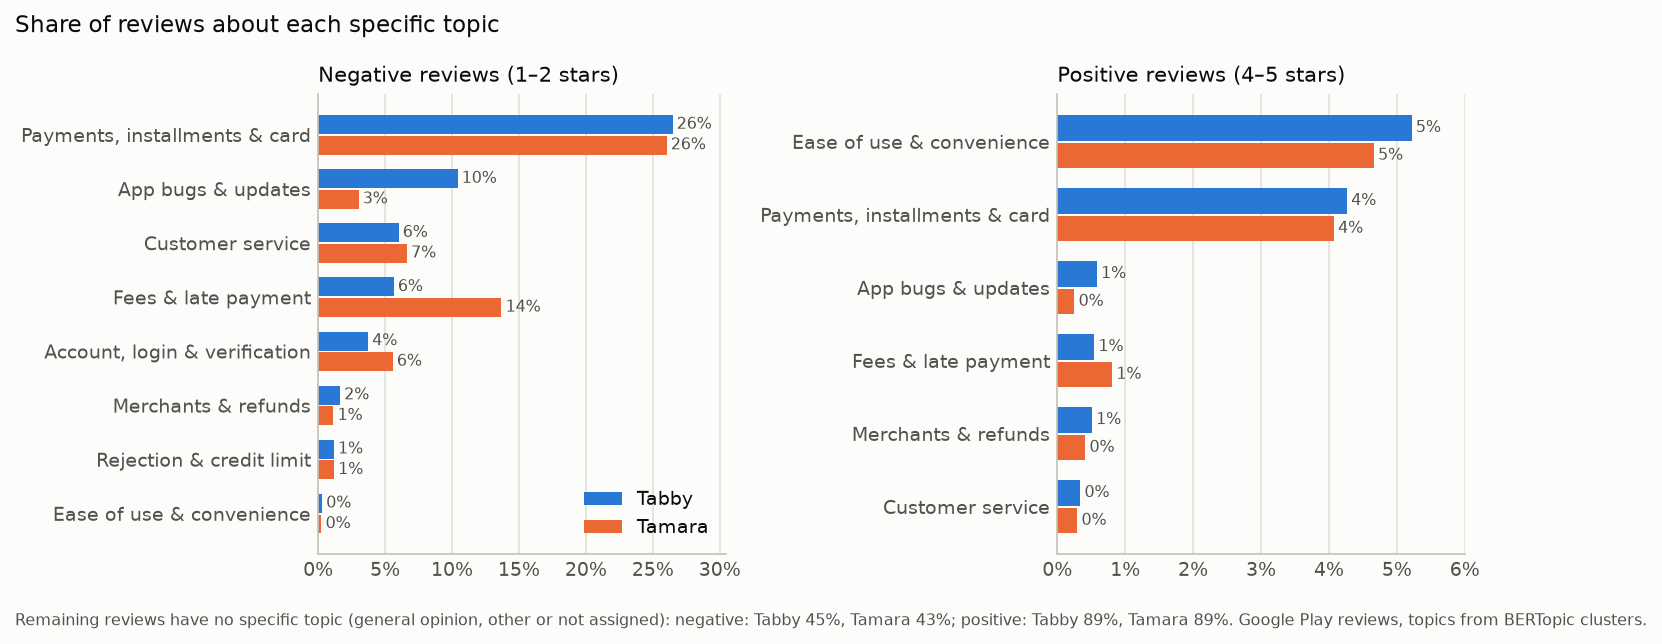

In [5]:
display(Image(filename=str(get_path("figures") / "topics_share.png")))

In [6]:
def share_wide(group: str, lang: str = "all") -> pd.DataFrame:
    """Topic shares (%) and review counts per app for one star group."""
    part = shares[(shares["group"] == group) & (shares["lang"] == lang)]
    pct = part.pivot(index="topic", columns="app", values="share").fillna(0).mul(100).round(1)
    n = part.pivot(index="topic", columns="app", values="n").fillna(0).astype(int)
    wide = pd.concat({"share (%)": pct, "reviews": n}, axis=1)
    return wide.sort_values(("share (%)", "all"), ascending=False).rename(index=topic_label)


share_wide("negative")

share (%)              reviews             
app                                      all tabby tamara     all tabby tamara
topic                                                                         
General opinion, no specific topic      30.7  30.8   30.5    4060  2796   1264
Payments, installments & card           26.3  26.5   26.0    3483  2403   1080
Not assigned                             9.5   9.4    9.7    1255   854    401
Fees & late payment                      8.2   5.6   13.7    1080   512    568
App bugs & updates                       8.1  10.4    3.0    1070   945    125
Customer service                         6.2   6.0    6.6     820   545    275
Account, login & verification            4.3   3.7    5.6     569   338    231
Other                                    3.8   4.4    2.4     503   404     99
Merchants & refunds                      1.5   1.6    1.1     195   148     47
Rejection & credit limit                 1.2   1.2    1.2     155   106     49
Ease of use & convenience                0.3   0.3    0.2      36    26     10

In [7]:
share_wide("positive")

share (%)              reviews              
app                                      all tabby tamara     all  tabby tamara
topic                                                                          
General opinion, no specific topic      83.7  83.4   84.4  135212  87292  47920
Ease of use & convenience                5.0   5.2    4.7    8110   5463   2647
Payments, installments & card            4.2   4.3    4.1    6779   4466   2313
Other                                    3.3   3.2    3.5    5326   3360   1966
Not assigned                             1.8   2.0    1.6    2977   2041    936
Fees & late payment                      0.6   0.5    0.8    1028    569    459
App bugs & updates                       0.5   0.6    0.2     753    610    143
Merchants & refunds                      0.5   0.5    0.4     767    533    234
Customer service                         0.3   0.3    0.3     521    354    167

## 3. Arabic and English reviews

Topic shares of negative reviews per app and language (%, then counts):

- **Fees and late payment** are more common in Arabic Tabby reviews (9.0%, 404 reviews) than in English ones (2.4%, 108). Tamara has a high share in both languages (14.4% and 12.7%).
- **Merchants and refunds** look almost English-only: for Tabby, 141 English reviews against 7 Arabic. That is mostly a clustering effect. Of the 232 Arabic negative reviews that mention a refund or a store, 144 fall into payments clusters (second table). The keyword rules find merchant and refund complaints in both languages: Tabby 72 Arabic and 109 English.

In [8]:
part = shares[(shares["group"] == "negative") & (shares["app"] != "all") & (shares["lang"] != "all")]
pct = part.pivot(index="topic", columns=["app", "lang"], values="share").fillna(0).mul(100).round(1)
n = part.pivot(index="topic", columns=["app", "lang"], values="n").fillna(0).astype(int)
pd.concat({"share (%)": pct, "reviews": n}, axis=1).rename(index=topic_label)

share (%)                        reviews                       
app                                    tabby         tamara           tabby         tamara        
lang                                  arabic english arabic english  arabic english arabic english
topic                                                                                             
Account, login & verification            3.3     4.2    4.6     7.1     146     192    115     115
App bugs & updates                      13.1     7.8    3.3     2.6     587     356     83      42
Rejection & credit limit                 1.4     0.9    1.5     0.7      64      42     38      11
Customer service                         5.0     7.0    5.6     8.4     226     319    140     135
Ease of use & convenience                0.4     0.1    0.4     0.1      20       6      9       1
Fees & late payment                      9.0     2.4   14.4    12.7     404     108    364     204
General opinion, no specific topic      29.8    31.8   30.7    30.3    1338    1456    774     489
Merchants & refunds                      0.2     3.1    0.2     2.6       7     141      5      42
Other                                    3.4     5.5    2.6     2.1     150     252     66      33
Payments, installments & card           25.7    27.1   27.6    23.1    1151    1238    697     373
Not assigned                             8.7    10.2    9.2    10.4     389     465    233     167

In [9]:
# Arabic negative reviews that mention a refund or a store, by cluster topic.
arabic = reviews[(reviews["group"] == "negative") & (reviews["lang"] == "arabic")]
mentions = arabic["text_norm"].str.contains("استرجاع|استرداد|ارجاع|مرتجع|المتجر|متجر|التاجر")
arabic.loc[mentions, "topic"].map(topic_label).value_counts().to_frame("reviews")

,reviews
topic,
"Payments, installments & card",144
Customer service,32
Fees & late payment,19
Not assigned,17
Merchants & refunds,6
"General opinion, no specific topic",4
"Account, login & verification",3
App bugs & updates,3
Other,3


## 4. Example reviews

Three random reviews of 5–40 words per specific topic. E-mail addresses, URLs and long numbers are masked.

In [10]:
def examples(group: str, n: int = 3, seed: int = 0) -> pd.DataFrame:
    """A few reviews of 5-40 words per specific topic, with e-mails, URLs and long numbers masked."""
    pool = reviews[(reviews["group"] == group) & ~reviews["topic"].isin(NO_TOPIC)]
    words = pool["text"].str.split().str.len()
    pool = pool[words.between(5, 40)]
    picked = pool.sample(frac=1, random_state=seed).groupby("topic").head(n).sort_values("topic", kind="stable")
    out = picked[["topic", "app", "lang", "rating", "text"]].copy()
    out["text"] = out["text"].map(scrub)
    out["topic"] = out["topic"].map(topic_label)
    return out.reset_index(drop=True)


examples("negative")

,topic,app,lang,rating,text
0,"Account, login & verification",tamara,arabic,1,زباااال كل مااحط رمز التحقق للهوية يطلع خطا مع اني حاط الرقم صحيح
1,"Account, login & verification",tabby,arabic,1,ما توصل رسايل رمز لي ولا اقدر افتح الموقع؟
2,"Account, login & verification",tamara,english,1,Doesn't provide face id with android devices
3,App bugs & updates,tabby,english,1,Need to re open the app like 20 times to get it to work.
4,App bugs & updates,tamara,arabic,1,أواجه صعوبه في تنزيل برنامج تمارا تأتي رساله على التطبيق لايتوافق جهازك مع هاذا الإصدار ماهي المشكله اريد ...
5,App bugs & updates,tabby,arabic,1,البرنامج لا يعمل يتم الدخول من أجل الدفع لا يظهر بيانات
6,Rejection & credit limit,tabby,arabic,1,لما اجي اسدد اخر دفعه يرفض ويطلب بطاقه ثانيه
7,Rejection & credit limit,tamara,arabic,1,تجربه سيئه اذا اردت طلبيه فوق 400 ريال يرفض التطبيق دون سبب واضح رغم انني اسدد اول باول ولا يوجد لدي متعثر...
8,Rejection & credit limit,tabby,english,1,My question is one time only one order only or more orders?
9,Customer service,tabby,english,1,No one is responding about my issue. Until now. It's been 3weeks already. But no one answering my issue. P...


In [11]:
examples("positive")

,topic,app,lang,rating,text
0,App bugs & updates,tabby,arabic,5,بعد التحديث الاخير. التطبيق لا يفتح اطلاقاً يرجى حل المشكلة
1,App bugs & updates,tabby,english,5,Today the apps didn't work
2,App bugs & updates,tabby,english,5,some time troubles to log in
3,Customer service,tabby,english,5,Shahzaib Raza Very Nice Support
4,Customer service,tabby,arabic,5,شكر وتقدير للاستاذة المميزة ( مرنة ) في خدمة العملاء على تعاملها الراقي وصبرها في حل الاشكالية التي كانت ل...
5,Customer service,tabby,english,5,thank you for your support 🙏🏻
6,Ease of use & convenience,tabby,english,5,it's very easy now to parchesing anything I highly recommend thank you tabby
7,Ease of use & convenience,tabby,arabic,5,ممتاز سهل الإستخدام بيحل جزء كبير من أعباء الأقساط طويلة المدى
8,Ease of use & convenience,tamara,english,5,Simple nd easy app thanks
9,Fees & late payment,tabby,arabic,5,أتمنى اذا تم تمديد الدفع لأسبوع وتم التسديد قبل الاسبوع ترجع الرسوم المتبقيه حق الايام المتبقيه


## 5. Topics over time

Quarterly counts of negative reviews for the six largest specific topics, for complete quarters only. Counts are shown rather than shares, because the number of reviews changes a lot over time.

**Tabby, July–August 2026.** Tabby's negative reviews rose to 367 in July and 557 in August 2026, against 136–238 in each of the other months from October 2025 to October 2026.

- Reviews about app bugs and updates went from about 18 a month in those other months to 123 in July and 257 in August.
- That is about 172 of the roughly 282 extra negative reviews a month, or 61% of the increase. The keyword rules give the same result (179 of 282).
- Payment complaints also doubled (from 42 to 94 a month), partly because the broad payments clusters take in some app complaints.

**Tamara, February 2026.** Tamara's negative reviews fell from about 113 a month (July 2025 to January 2026) to 71 (February to October 2026).

- Most of the drop is in general-opinion reviews: from 45 to 12 a month.
- Reviews with a specific topic changed little: from 55 to 50 a month. Account, app and rejection complaints rose slightly.
- With the fall in positive reviews at the same time, this suggests that fewer casual raters were reviewing, rather than that problems decreased. This is not confirmed.

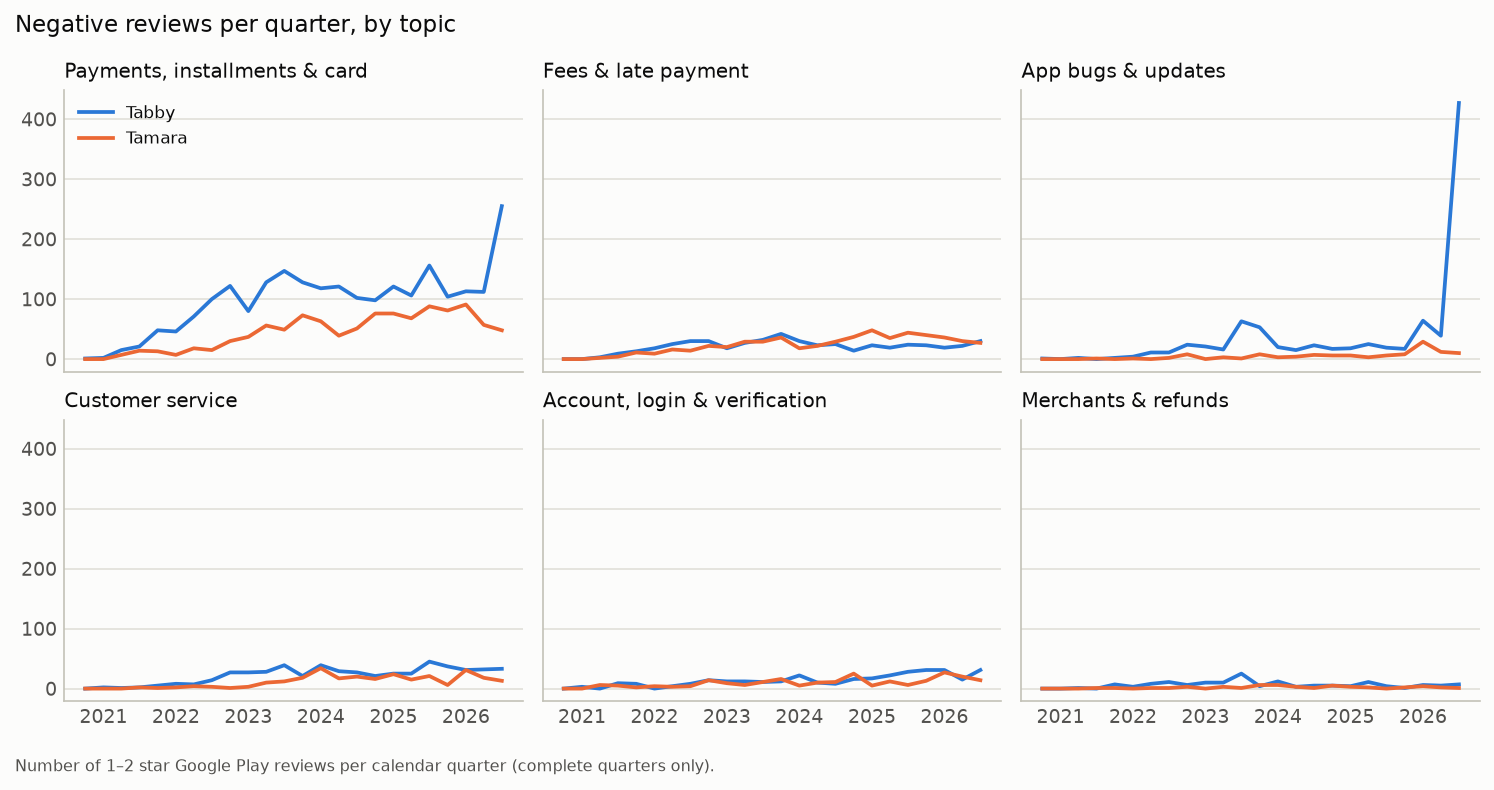

In [12]:
display(Image(filename=str(get_path("figures") / "topics_negative_by_quarter.png")))

In [13]:
negative = reviews[reviews["group"] == "negative"]
tabby = negative[(negative["app"] == "tabby") & negative["month"].between("2025-10-01", "2026-10-01")]
pd.crosstab(tabby["topic"].map(topic_label), tabby["month"].dt.strftime("%Y-%m"), margins=True)

month,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,All
topic,,,,,,,,,,,,,,
"Account, login & verification",10,8,13,11,12,8,8,5,2,7,14,10,8,116
App bugs & updates,6,7,4,7,53,4,25,8,6,123,257,47,31,578
Customer service,16,9,12,13,11,7,10,11,11,16,13,4,13,146
Ease of use & convenience,1,1,0,0,2,1,0,1,1,0,1,0,2,10
Fees & late payment,10,8,5,6,7,6,7,5,10,12,12,6,9,103
"General opinion, no specific topic",89,84,77,60,74,53,46,59,79,98,98,83,68,968
Merchants & refunds,1,0,0,0,5,1,1,3,1,3,2,2,0,19
Not assigned,11,7,13,15,13,18,12,13,24,25,40,15,24,230
Other,8,11,7,8,10,5,3,4,2,7,7,3,5,80


In [14]:
# Reviews a month in July-August 2026 against the other months from October 2025 to October 2026.
spike = tabby["month"].isin(pd.to_datetime(["2026-07-01", "2026-08-01"]))
excess = pd.DataFrame({
    "jul_aug_per_month": tabby.loc[spike, "topic"].value_counts() / 2,
    "other_months_per_month": tabby.loc[~spike, "topic"].value_counts() / tabby.loc[~spike, "month"].nunique(),
}).fillna(0)
excess["excess"] = excess["jul_aug_per_month"] - excess["other_months_per_month"]
excess["share_of_excess"] = excess["excess"] / excess["excess"].sum()
excess.sort_values("excess", ascending=False).rename(index=topic_label).round(2)

,jul_aug_per_month,other_months_per_month,excess,share_of_excess
topic,,,,
App bugs & updates,190.0,18.00,172.00,0.61
"Payments, installments & card",93.5,41.91,51.59,0.18
"General opinion, no specific topic",98.0,70.18,27.82,0.10
Not assigned,32.5,15.00,17.50,0.06
Fees & late payment,12.0,7.18,4.82,0.02
Customer service,14.5,10.64,3.86,0.01
"Account, login & verification",10.5,8.64,1.86,0.01
Merchants & refunds,2.5,1.27,1.23,0.00
Other,7.0,6.00,1.00,0.00


In [15]:
# Tamara's negative reviews a month before and after February 2026, by topic.
tamara = negative[(negative["app"] == "tamara") & negative["month"].between("2025-07-01", "2026-10-01")]
period = tamara["month"].lt("2026-02-01").map({True: "Jul 2025-Jan 2026", False: "Feb-Oct 2026"})
counts = pd.crosstab(tamara["topic"], period)[["Jul 2025-Jan 2026", "Feb-Oct 2026"]]
months = tamara.groupby(period)["month"].nunique().reindex(counts.columns)
per_month = counts.div(months.to_numpy(), axis=1)
specific = ~per_month.index.isin(NO_TOPIC)
per_month.loc["all specific topics"] = per_month[specific].sum()
per_month.round(1).rename(index=topic_label)

month,Jul 2025-Jan 2026,Feb-Oct 2026
topic,,
"Account, login & verification",3.7,6.3
App bugs & updates,3.0,5.4
Rejection & credit limit,0.3,1.7
Customer service,5.7,5.8
Ease of use & convenience,0.3,0.0
Fees & late payment,13.6,10.0
"General opinion, no specific topic",44.7,11.7
Merchants & refunds,0.4,0.8
Other,2.1,1.7


## 6. Check against hand labels

This check uses the 290 usable gold reviews with 1–2 or 4–5 stars (155 negative, 135 positive), each with a hand-labeled main topic. Three-star reviews have no topic model. As a benchmark, the same labeler's two labelings of 48 reviews agreed with a topic kappa of 0.84.

**The keyword lists were revised once, after a first look at this check.**

- The fixes used words seen in the cluster keywords that were missing or too broad:
  - Arabic negated forms such as لايعمل and لايفتح, and "slow";
  - Gulf and misspelled praise words such as زين, نايس and متاز;
  - two Arabic words for months;
  - `install*`, which also matched "installment".
- This renamed 5 negative clusters (367 reviews) and 12 positive clusters (12,163 reviews), mostly from *other* to *general*.
- The model settings were not changed.
- Cohen's kappa before → after the revision:

  | | All | Negative | Positive |
  |---|---|---|---|
  | Clusters | 0.41 → 0.42 | 0.35 → 0.35 | 0.20 → 0.25 |
  | Keyword rules | 0.47 → 0.49 | 0.47 → 0.49 | 0.13 → 0.14 |

**Results (after the revision):**

- **Clustering does not help to find a review's main topic.** On negative reviews, kappa is 0.35 for the clusters and 0.49 for the keyword rules alone. On positive reviews, the clusters do better (0.25 against 0.14), but nearly all of them are general praise.
- **Both methods find app problems too rarely** (recall 0.32 for both, over all 290 reviews).
- **Both find payments too often** (precision 0.20 for clusters, 0.33 for keyword rules). Many complaints mention a payment in passing, and both methods pick a specific topic whenever its words carry enough weight.
- **Hand labels give different shares.** Topic shares from the hand labels (weighted to the population mix of apps and languages, 155 reviews) put app bugs and updates at 22% of negative reviews and customer service at 15%. The clusters give 8% and 6%. For payments it is the other way round: 12% from hand labels, 26% from clusters.

The hand-label estimates come from a small sample, but they show that cluster shares understate app and service complaints and overstate payments.

In [16]:
overall = evaluation[evaluation["topic"] == "all"].pivot(index=["group", "metric"], columns="method", values="value")
overall.round(3)

method                        clusters  keywords
group    metric                                 
all      accuracy                0.624     0.648
         kappa                   0.425     0.488
         specific_vs_general     0.821     0.876
negative accuracy                0.452     0.561
         kappa                   0.345     0.488
         specific_vs_general     0.781     0.884
positive accuracy                0.822     0.748
         kappa                   0.249     0.138
         specific_vs_general     0.867     0.867

In [17]:
by_topic = evaluation[(evaluation["topic"] != "all") & (evaluation["group"] == "all")]
by_topic.pivot(index=["topic", "n"], columns=["method", "metric"], values="value").round(2)

method                     clusters               keywords             
metric                    precision recall    f1 precision recall    f1
topic                 n                                                
app_technical         31       0.83   0.32  0.47      0.71   0.32  0.44
customer_service      27       0.64   0.33  0.44      0.93   0.52  0.67
ease_of_use           10       0.30   0.30  0.30      0.36   0.40  0.38
general               177      0.93   0.81  0.87      0.96   0.75  0.84
payments_installments 20       0.20   0.50  0.29      0.33   0.65  0.44

In [18]:
# Hand-labeled topic (rows) against the cluster topic (columns), negative gold reviews.
gold = gold_topics(reviews)
neg_gold = gold[gold["group"] == "negative"]
pd.crosstab(neg_gold["hand"].map(topic_label), neg_gold["topic"].map(topic_label), margins=True)

topic,"Account, login & verification",App bugs & updates,Customer service,Ease of use & convenience,Fees & late payment,"General opinion, no specific topic",Merchants & refunds,Not assigned,Other,"Payments, installments & card",Rejection & credit limit,All
hand,,,,,,,,,,,,
"Account, login & verification",2,0,0,0,0,0,0,0,1,4,1,8
App bugs & updates,3,10,0,0,0,3,0,3,0,11,0,30
Customer service,3,0,9,0,1,1,2,1,0,8,0,25
Ease of use & convenience,0,1,0,0,1,1,0,0,0,2,0,5
Fees & late payment,1,0,0,0,4,0,0,2,0,1,0,8
"General opinion, no specific topic",0,0,5,1,5,35,0,1,2,2,0,51
Merchants & refunds,0,0,0,0,0,0,0,0,0,1,0,1
Other,1,0,0,0,0,1,0,0,0,0,0,2
"Payments, installments & card",0,1,0,0,2,1,1,4,0,10,0,19


In [19]:
def method_table(group: str) -> pd.DataFrame:
    """Topic shares (%) and counts from clusters, keyword rules and weighted hand labels."""
    part = methods[methods["group"] == group]
    pct = part.pivot(index="topic", columns="method", values="share").mul(100).round(1)
    n = part.pivot(index="topic", columns="method", values="n").astype("Int64")
    wide = pd.concat({"share (%)": pct, "reviews": n}, axis=1)
    return wide.sort_values(("share (%)", "hand_labels"), ascending=False).rename(index=topic_label)


method_table("negative")

share (%)                       reviews                     
method                              clusters hand_labels keywords clusters hand_labels keywords
topic                                                                                          
General opinion, no specific topic      30.7        31.5     25.4     4060          51     3356
App bugs & updates                       8.1        21.8      7.8     1070          30     1032
Customer service                         6.2        15.0      9.0      820          25     1195
Payments, installments & card           26.3        11.8     20.8     3483          19     2746
Fees & late payment                      8.2         5.1      5.7     1080           8      753
Rejection & credit limit                 1.2         4.8      6.9      155           6      909
Account, login & verification            4.3         4.4      6.0      569           8      792
Ease of use & convenience                0.3         3.3      1.0       36           5      132
Other                                    3.8         1.4     15.3      503           2     2020
Merchants & refunds                      1.5         0.9      2.2      195           1      291
Not assigned                             9.5         NaN      NaN     1255        <NA>     <NA>

In [20]:
method_table("positive")

share (%)                       reviews                     
method                              clusters hand_labels keywords clusters hand_labels keywords
topic                                                                                          
General opinion, no specific topic      83.7        92.4     75.8   135212         126   122393
Ease of use & convenience                5.0         4.4      7.1     8110           5    11494
Customer service                         0.3         1.5      0.6      521           2     1034
App bugs & updates                       0.5         1.0      0.4      753           1      558
Payments, installments & card            4.2         0.6      4.2     6779           1     6792
Account, login & verification            NaN         NaN      0.2     <NA>        <NA>      283
Rejection & credit limit                 NaN         NaN      0.3     <NA>        <NA>      428
Fees & late payment                      0.6         NaN      0.9     1028        <NA>     1416
Merchants & refunds                      0.5         NaN      0.3      767        <NA>      451
Other                                    3.3         NaN     10.3     5326        <NA>    16624
Not assigned                             1.8         NaN      NaN     2977        <NA>     <NA>

In [21]:
# Hand-labeled app problems that the clusters gave another topic.
missed = neg_gold[(neg_gold["hand"] == "app_technical") & (neg_gold["topic"] != "app_technical")]
out = missed[["app", "lang", "topic", "keyword_topic", "text"]].head(8).copy()
out["text"] = out["text"].map(scrub)
out

,app,lang,topic,keyword_topic,text
2,tabby,arabic,unassigned,other,ما تظهر طريقه الدفع في مواقع ثانيه
12,tabby,english,general,other,Not working
25,tabby,english,payments_installments,app_technical,Partial top up option again revoked in latest update. This is not good for Tabby community.
28,tabby,english,unassigned,other,very disaapointed !!! i win the raffle draw for emirates flight draw voucher and then suddenly taking it b...
32,tabby,arabic,payments_installments,payments_installments,الحين ليه دايم معلق كيف نقدر نشيك مدفوعاتنا غير السحب الآلي مافي أمان بس تحط بطاقتك يصير يسحب. كل شهر بدون...
39,tamara,english,payments_installments,merchant_refund,"Hi i need an update to this apps i couldn't reach the number that was provided, i need someone to assist m..."
43,tamara,arabic,payments_installments,payments_installments,عند وصلي لدفع المبلغ تطلع رساله عملية غير ناجحه اش السبب ماني عارف رغم وجود مبلغ كافي لإتمام العملية
50,tabby,arabic,payments_installments,app_technical,للأسف مع آخر تحديثات للبرنامج صار مايفتح تطلع صفحه بيضا فقط نرجو حل هذي المشكله


## 7. Summary

- **Negative reviews.** Clusters capture problems that have their own vocabulary well: a blocked card, OTP codes, a white screen, late fees, refunds. Long mixed complaints end up in broad payments clusters. By the hand labels, app problems (22%) and customer service (15%) are the largest specific complaint topics, and payments come third (12%).
- **Between apps,** the clusters, the keyword rules and the hand labels agree on the direction: app bugs are a larger share of Tabby's complaints (hand labels 20 of 76 against 10 of 79), and fees a larger share of Tamara's (hand labels 5 of 79 against 3 of 76, too few to be sure).
- **Over time,** Tabby's July–August 2026 spike is mostly app bugs and updates. Tamara's fall in negative reviews after February 2026 is mostly in general-opinion reviews.
- **Positive reviews** are mostly general praise; ease of use is the main specific theme (5%).
- **Against hand labels,** keyword rules alone agree at least as well as BERTopic clusters on negative reviews (kappa 0.49 against 0.35, with 0.84 for the same labeler's consistency). The clusters are more useful for exploring what people write about than for labeling single reviews.